In [1]:
#Import Library
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
RS = 42
URUTAN = ["Valuasi Relatif Rendah", "Valuasi Relatif Sedang", "Valuasi Relatif Tinggi"]

In [2]:
#Konfigurasi Data
# "positif" : hanya saham dengan PER > 0 dan PBV > 0, winsorizing atas P95 (sesuai proposal)
# "semua"   : seluruh saham kecuali yang tidak memiliki nilai (FREN),
#             winsorizing dua sisi P5-P95 karena ada nilai negatif ekstrem
DATA = "positif"
P_BAWAH = 5 if DATA == "semua" else None
print(f"Data yang digunakan: {DATA}")

Data yang digunakan: positif


In [3]:
#Dataset
df = pd.read_excel("Dataset September.xlsx")
df = df[["Kode Saham", "Sektor", "PER", "PBV", "ROE %", "DER"]].copy()

df.loc[df["Kode Saham"] == "KETR", "Sektor"] = "Infrastructures"
df.loc[df["Kode Saham"] == "VICI", "Sektor"] = "Consumer Non-Cyclicals"

print(f"Jumlah data   : {len(df)} saham")
print(f"Jumlah sektor : {df['Sektor'].nunique()}")
df.head()

Jumlah data   : 960 saham
Jumlah sektor : 11


,Kode Saham,Sektor,PER,PBV,ROE %,DER
0,AADI,Energy,6.10,1.13,18.58,0.53
1,AALI,Consumer Non-Cyclicals,7.39,0.56,7.59,0.17
2,ABBA,Consumer Cyclicals,-4.78,-0.99,0.00,-2.87
3,ABDA,Financials,17.52,1.32,7.54,0.58
4,ABMM,Industrials,5.11,0.46,8.99,1.30


In [4]:
mv = pd.DataFrame({"jumlah_missing": df.isna().sum(),
                   "persen": (df.isna().mean() * 100).round(3)})
print(mv)
print(f"\nTotal baris yang memuat missing value: {df.isna().any(axis=1).sum()}")
df[df.isna().any(axis=1)]

            jumlah_missing  persen
Kode Saham               0   0.000
Sektor                   0   0.000
PER                      1   0.104
PBV                      1   0.104
ROE %                    1   0.104
DER                      1   0.104

Total baris yang memuat missing value: 1


,Kode Saham,Sektor,PER,PBV,ROE %,DER
328,FREN,Infrastructures,NaN,NaN,NaN,NaN


In [5]:
#Penanganan Missing Value
n_awal = len(df)
df = df.dropna(subset=["PER", "PBV"]).reset_index(drop=True)
print(f"Sebelum: {n_awal} | Sesudah: {len(df)} | Dihapus: {n_awal - len(df)}")
print(f"Sisa missing value: {df[['PER', 'PBV']].isna().sum().sum()}")

Sebelum: 960 | Sesudah: 959 | Dihapus: 1
Sisa missing value: 0


In [6]:
n_sebelum = len(df)
print(f"PER <= 0 : {(df['PER'] <= 0).sum()} saham")
print(f"PBV <= 0 : {(df['PBV'] <= 0).sum()} saham")

if DATA == "positif":
    df = df[(df["PER"] > 0) & (df["PBV"] > 0)].reset_index(drop=True)
else:
    print("\nDATA = 'semua': saham dengan PER/PBV <= 0 tetap digunakan")
print(f"\nSebelum: {n_sebelum} | Sesudah: {len(df)} | Dihapus: {n_sebelum - len(df)}")

PER <= 0 : 325 saham
PBV <= 0 : 52 saham

Sebelum: 959 | Sesudah: 627 | Dihapus: 332


In [7]:
#Winsorizing Upper Only  P95
n = len(df)
L = 1 + (n - 1) * 0.95
print(f"n = {n}  ->  L = 1 + ({n}-1) x 0,95 = {L:.4f}\n")

for c in ["PER", "PBV"]:
    urut = np.sort(df[c].values)
    i = int(L)
    batas = np.percentile(df[c], 95)
    bawah = np.percentile(df[c], P_BAWAH) if P_BAWAH else -np.inf
    n_cap = ((df[c] > batas) | (df[c] < bawah)).sum()
    df[c + "_w"] = np.clip(df[c], bawah, batas)
    print(f"{c}: X{i} = {urut[i-1]:.4f}, X{i+1} = {urut[i]:.4f}  ->  "
          f"P95 = {batas:.4f}" + (f", P{P_BAWAH} = {bawah:.4f}" if P_BAWAH else "")
          + f"  ({n_cap} saham dipotong)")

df[["PER", "PER_w", "PBV", "PBV_w"]].describe().T

n = 627  ->  L = 1 + (627-1) x 0,95 = 595.7000

PER: X595 = 201.8700, X596 = 232.9900  ->  P95 = 223.6540  (32 saham dipotong)
PBV: X595 = 9.9500, X596 = 9.9600  ->  P95 = 9.9570  (32 saham dipotong)


,count,mean,std,min,25%,50%,75%,max
PER,627.0,123.837767,1262.702939,0.31,8.295,14.51,40.125,30826.300
PER_w,627.0,38.892772,55.373035,0.31,8.295,14.51,40.125,223.654
PBV,627.0,3.865263,17.568178,0.04,0.650,1.20,2.260,302.810
PBV_w,627.0,2.169416,2.542534,0.04,0.650,1.20,2.260,9.957


In [8]:
#Standardisasi Relatif Sektor
stat_sektor = df.groupby("Sektor").agg(
    n=("Kode Saham", "count"),
    mu_PER=("PER_w", "mean"), sigma_PER=("PER_w", lambda s: s.std(ddof=1)),
    mu_PBV=("PBV_w", "mean"), sigma_PBV=("PBV_w", lambda s: s.std(ddof=1)))
stat_sektor

,n,mu_PER,sigma_PER,mu_PBV,sigma_PBV
Sektor,,,,,
Basic Materials,78,28.620487,43.084087,1.574410,1.808714
Consumer Cyclicals,82,39.509951,55.464288,2.197744,2.708793
Consumer Non-Cyclicals,96,34.160250,55.498278,2.810302,2.985784
Energy,66,39.612909,55.887190,2.871545,3.166548
Financials,82,35.142585,47.645600,1.440976,1.801953
Healthcare,32,55.649875,74.551417,2.553031,2.182104
Industrials,42,31.637238,44.880256,2.371690,2.830841
Infrastructures,40,37.846200,55.469202,2.382025,2.580538
Properties & Real Estate,52,39.809808,44.656754,1.301346,1.320141


In [9]:
g = df.groupby("Sektor")
for c in ["PER", "PBV"]:
    df[c + "_z"] = g[c + "_w"].transform(lambda s: (s - s.mean()) / s.std(ddof=1))

X_k = df[["PER_z", "PBV_z"]].values

# verifikasi: mean tiap sektor harus 0, std harus 1
cek = df.groupby("Sektor")[["PER_z", "PBV_z"]].agg(["mean", "std"]).round(4)
print("Verifikasi (mean ~0, std ~1):")
cek

Verifikasi (mean ~0, std ~1):


PER_z      PBV_z     
                           mean  std  mean  std
Sektor                                         
Basic Materials            -0.0  1.0   0.0  1.0
Consumer Cyclicals          0.0  1.0  -0.0  1.0
Consumer Non-Cyclicals     -0.0  1.0   0.0  1.0
Energy                      0.0  1.0  -0.0  1.0
Financials                 -0.0  1.0   0.0  1.0
Healthcare                  0.0  1.0  -0.0  1.0
Industrials                 0.0  1.0  -0.0  1.0
Infrastructures            -0.0  1.0   0.0  1.0
Properties & Real Estate    0.0  1.0  -0.0  1.0
Technology                 -0.0  1.0  -0.0  1.0
Transportation & Logistic   0.0  1.0  -0.0  1.0

 K       WCSS  Silhouette      DBI
 2 539.809760    0.682842 0.762997
 3 374.829275    0.673138 0.796910
 4 241.527805    0.657924 0.664548
 5 188.894896    0.536723 0.742813
 6 160.216206    0.540202 0.739080

Silhouette tertinggi : K = 2
DBI terendah         : K = 4
Silhouette K = 3     : 0.6731 -> memenuhi >= 0,51, K = 3 digunakan
K pembanding analisis sensitivitas: 4


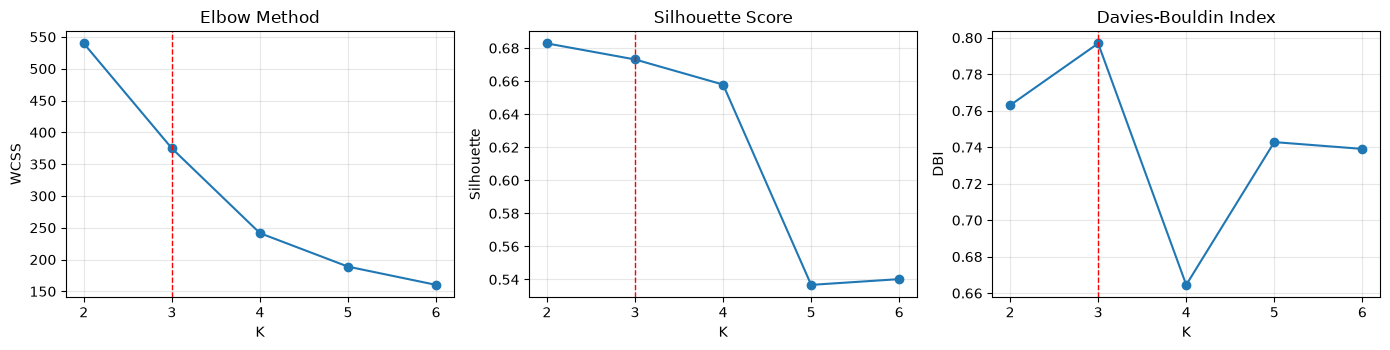

In [10]:
#K-Means Clustering
hasil = []
for k in range(2, 7):
    km = KMeans(n_clusters=k, n_init=50, random_state=RS).fit(X_k)
    hasil.append({"K": k, "WCSS": km.inertia_,
                  "Silhouette": silhouette_score(X_k, km.labels_),
                  "DBI": davies_bouldin_score(X_k, km.labels_)})
df_k = pd.DataFrame(hasil)
print(df_k.to_string(index=False))

k_sil = int(df_k.loc[df_k.Silhouette.idxmax(), "K"])
k_dbi = int(df_k.loc[df_k.DBI.idxmin(), "K"])
sil_3 = df_k.loc[df_k.K == 3, "Silhouette"].item()
print(f"\nSilhouette tertinggi : K = {k_sil}")
print(f"DBI terendah         : K = {k_dbi}")
print(f"Silhouette K = 3     : {sil_3:.4f} -> "
      + ("memenuhi >= 0,51, K = 3 digunakan" if sil_3 >= 0.51 else "di bawah 0,51"))

# K = 2 (Silhouette) hanya membentuk kategori Rendah dan Tinggi, jadi analisis
# sensitivitas memakai K = 4 (saran DBI dan Elbow) sebagai pembanding.
K_PEMBANDING = 4
print(f"K pembanding analisis sensitivitas: {K_PEMBANDING}")

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for a, col, judul in zip(ax, ["WCSS", "Silhouette", "DBI"],
                         ["Elbow Method", "Silhouette Score", "Davies-Bouldin Index"]):
    a.plot(df_k.K, df_k[col], marker="o")
    a.axvline(3, color="red", ls="--", lw=1)
    a.set(title=judul, xlabel="K", ylabel=col, xticks=df_k.K)
    a.grid(alpha=.3)
plt.tight_layout(); plt.show()

In [11]:
K = 3
kmeans = KMeans(n_clusters=K, n_init=50, random_state=RS).fit(X_k)
df["cluster"] = kmeans.labels_

print(f"WCSS       : {kmeans.inertia_:.4f}")
print(f"Silhouette : {silhouette_score(X_k, df['cluster']):.4f}")
print(f"DBI        : {davies_bouldin_score(X_k, df['cluster']):.4f}")
print(f"Iterasi    : {kmeans.n_iter_}")

centroid = pd.DataFrame(kmeans.cluster_centers_, columns=["PER_z", "PBV_z"])
centroid["jumlah"] = df["cluster"].value_counts().sort_index()
centroid

WCSS       : 374.8293
Silhouette : 0.6731
DBI        : 0.7969
Iterasi    : 8


,PER_z,PBV_z,jumlah
0,-0.376982,-0.323966,511
1,2.105211,-0.049126,45
2,1.378916,2.362779,71


In [12]:
def beri_label(centroid):
    skor = centroid.mean(axis=1)                 # rata-rata PERz dan PBVz centroid
    urut = np.argsort(skor)                      # skor terendah -> tertinggi
    label = {int(i): "Valuasi Relatif Sedang" for i in urut}
    label[int(urut[0])] = "Valuasi Relatif Rendah"
    label[int(urut[-1])] = "Valuasi Relatif Tinggi"
    return label, skor


c = kmeans.cluster_centers_
label, skor = beri_label(c)
for i in np.argsort(skor):
    print(f"Cluster {i}: PERz = {c[i,0]:+.4f}, PBVz = {c[i,1]:+.4f}, "
          f"skor = {skor[i]:+.4f}  ->  {label[i]}")

df["label"] = df["cluster"].map(label)

Cluster 0: PERz = -0.3770, PBVz = -0.3240, skor = -0.3505  ->  Valuasi Relatif Rendah
Cluster 1: PERz = +2.1052, PBVz = -0.0491, skor = +1.0280  ->  Valuasi Relatif Sedang
Cluster 2: PERz = +1.3789, PBVz = +2.3628, skor = +1.8708  ->  Valuasi Relatif Tinggi


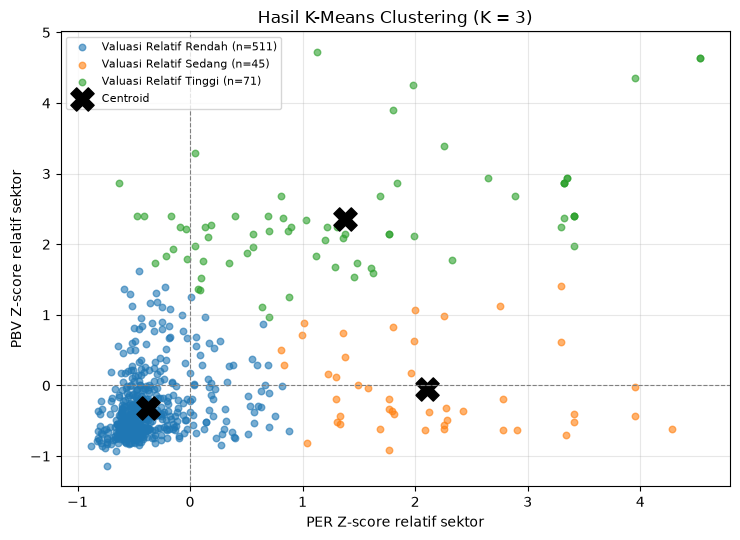

In [13]:
fig, ax = plt.subplots(figsize=(7.5, 5.5))
for i in range(K):
    m = df["cluster"] == i
    ax.scatter(df.loc[m, "PER_z"], df.loc[m, "PBV_z"], s=22, alpha=.6,
               label=f"{label[i]} (n={m.sum()})")
ax.scatter(c[:, 0], c[:, 1], marker="X", s=280, c="black", label="Centroid")
ax.axhline(0, color="gray", ls="--", lw=.8); ax.axvline(0, color="gray", ls="--", lw=.8)
ax.set(xlabel="PER Z-score relatif sektor", ylabel="PBV Z-score relatif sektor",
       title="Hasil K-Means Clustering (K = 3)")
ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

In [14]:
#Analisis Hasil Clustering
df["silhouette"] = silhouette_samples(X_k, df["cluster"])
ringkasan = pd.DataFrame({
    "jumlah": df["label"].value_counts(),
    "proporsi (%)": (df["label"].value_counts(normalize=True) * 100).round(2),
    "silhouette rata-rata": df.groupby("label")["silhouette"].mean().round(4),
}).reindex(URUTAN)
ringkasan

,jumlah,proporsi (%),silhouette rata-rata
label,,,
Valuasi Relatif Rendah,511,81.50,0.7455
Valuasi Relatif Sedang,45,7.18,0.4215
Valuasi Relatif Tinggi,71,11.32,0.3116


In [15]:
#Profil Cluster
posisi = (pd.DataFrame(c, columns=["PERz centroid", "PBVz centroid"])
          .rename(index=label).reindex(URUTAN).round(4))
print("Posisi centroid (skala Z):")
print(posisi, "\n")

profil = df.groupby("label")[["PER_w", "PBV_w"]].agg(["mean", "median", "min", "max"])
profil.reindex(URUTAN).round(4)

Posisi centroid (skala Z):
                        PERz centroid  PBVz centroid
Valuasi Relatif Rendah        -0.3770        -0.3240
Valuasi Relatif Sedang         2.1052        -0.0491
Valuasi Relatif Tinggi         1.3789         2.3628 



PER_w                           PBV_w               \
                            mean  median    min      max    mean median   min   
label                                                                           
Valuasi Relatif Rendah   17.8925   11.80   0.31   93.050  1.3596   1.01  0.04   
Valuasi Relatif Sedang  158.3113  148.41  64.45  223.654  1.9438   1.37  0.12   
Valuasi Relatif Tinggi  114.3480   93.20   4.58  223.654  8.1408   9.29  2.59   

                               
                          max  
label                          
Valuasi Relatif Rendah  7.080  
Valuasi Relatif Sedang  7.310  
Valuasi Relatif Tinggi  9.957

label                      Valuasi Relatif Rendah  Valuasi Relatif Sedang  \
Sektor                                                                      
Basic Materials                                68                       4   
Consumer Cyclicals                             67                       5   
Consumer Non-Cyclicals                         78                       4   
Energy                                         52                       4   
Financials                                     69                       7   
Healthcare                                     25                       4   
Industrials                                    35                       2   
Infrastructures                                35                       1   
Properties & Real Estate                       37                       7   
Technology                                     21                       4   
Transportation & Logistic                      24                       3   

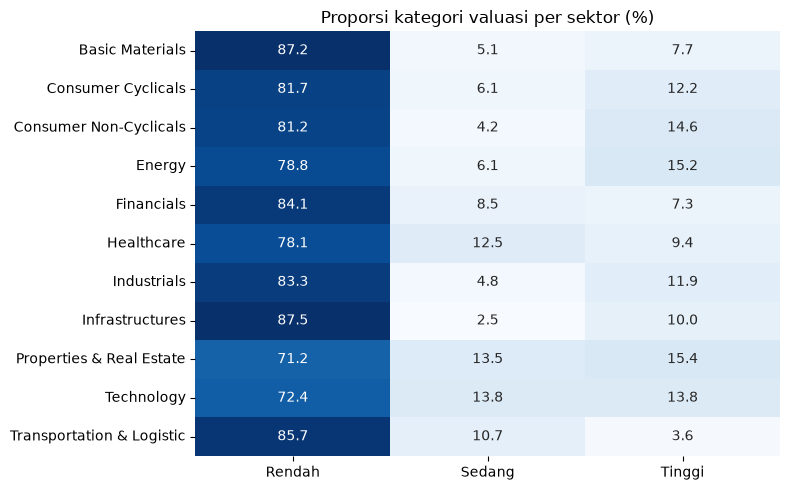

In [16]:
#Tabulasi Silang Label Cluster dan Sektor IDX-IC
tabulasi = pd.crosstab(df["Sektor"], df["label"]).reindex(columns=URUTAN, fill_value=0)
tabulasi["Total"] = tabulasi.sum(axis=1)
print(tabulasi, "\n")

persen = pd.crosstab(df["Sektor"], df["label"], normalize="index").reindex(columns=URUTAN) * 100
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(persen, annot=True, fmt=".1f", cmap="Blues", cbar=False, ax=ax,
            xticklabels=[k.replace("Valuasi Relatif ", "") for k in URUTAN])
ax.set(title="Proporsi kategori valuasi per sektor (%)", xlabel="", ylabel="")
plt.tight_layout(); plt.show()

Profil cluster K = 3:
          Label    n  Proporsi (%)   Z-PER   Z-PBV  PER_med  PBV_med  ROE_med  DER_med
Cluster                                                                               
0        Rendah  511          81.5 -0.3770 -0.3240    11.80     1.01     8.24     0.69
1        Sedang   45           7.2  2.1052 -0.0491   148.41     1.37     0.87     0.52
2        Tinggi   71          11.3  1.3789  2.3628    93.20     9.29    10.02     1.28 

Profil cluster K = 4:
                                   Label    n  Proporsi (%)   Z-PER   Z-PBV  PER_med  PBV_med  ROE_med  DER_med
Cluster                                                                                                        
0                                 Rendah  477          76.1 -0.3942 -0.4118   11.040    0.950     8.06     0.69
1        Sedang (PER setara, PBV tinggi)   83          13.2  0.2764  1.4885   44.210    5.520    13.53     0.99
3        Sedang (PER tinggi, PBV setara)   40           6.4  2.1946 -0.

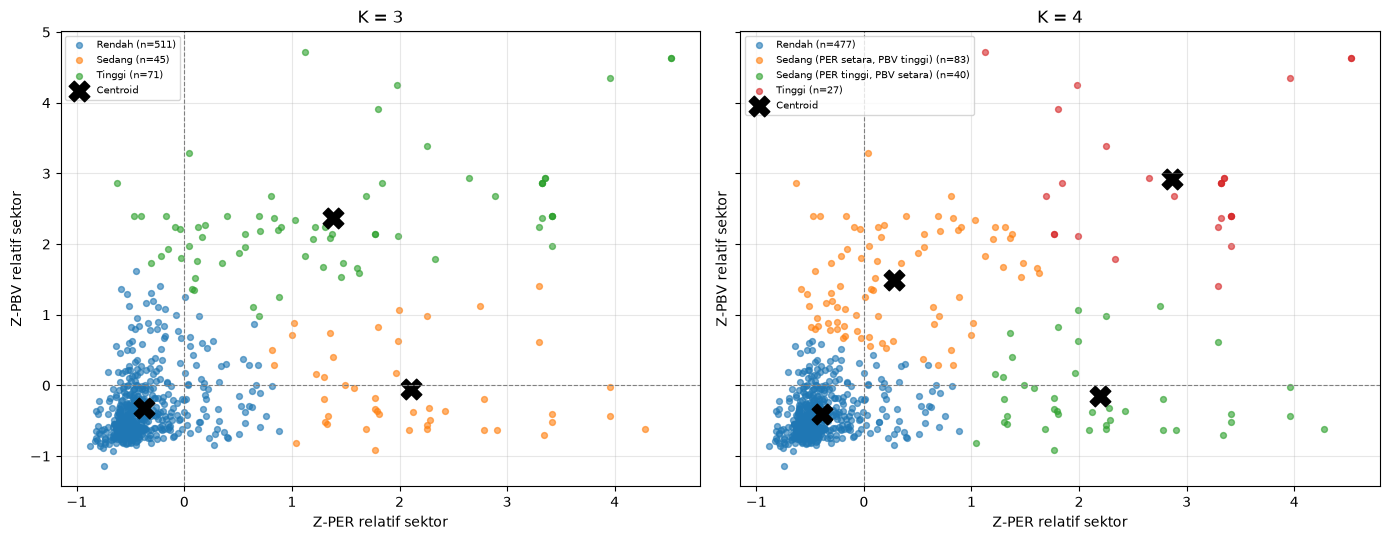

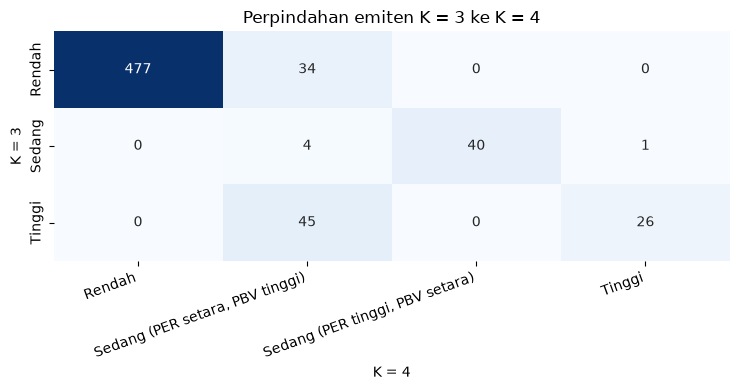

In [17]:
#Analisis Sensitivitas K = 3 vs K = 4 (Clustering)
def nama_label(centroid):
    """Label 3.1.6; bila ada lebih dari satu cluster Sedang, dibedakan menurut posisi centroid."""
    lab, skor_k = beri_label(centroid)
    tengah = [int(i) for i in np.argsort(skor_k)][1:-1]
    if len(tengah) > 1:
        arah = lambda z: "tinggi" if z > 0.5 else "rendah" if z < -0.5 else "setara"
        for i in tengah:
            lab[i] = (f"Valuasi Relatif Sedang (PER {arah(centroid[i, 0])}, "
                      f"PBV {arah(centroid[i, 1])})")
    return lab, skor_k


def profil_k(km_k):
    lab, skor_k = nama_label(km_k.cluster_centers_)
    d = df.assign(c=km_k.labels_)
    prof = d.groupby("c").agg(n=("Kode Saham", "count"),
                              PER_med=("PER", "median"), PBV_med=("PBV", "median"),
                              ROE_med=("ROE %", "median"), DER_med=("DER", "median"))
    prof.insert(0, "Label", pd.Series(lab).str.replace("Valuasi Relatif ", ""))
    prof.insert(2, "Proporsi (%)", (prof["n"] / len(d) * 100).round(1))
    prof.insert(3, "Z-PER", km_k.cluster_centers_[prof.index, 0])
    prof.insert(4, "Z-PBV", km_k.cluster_centers_[prof.index, 1])
    prof = prof.loc[np.argsort(skor_k)]
    prof.index.name = "Cluster"
    return lab, prof


km_4 = KMeans(n_clusters=K_PEMBANDING, n_init=50, random_state=RS).fit(X_k)
label_3, profil_3 = profil_k(kmeans)
label_4, profil_4 = profil_k(km_4)
df["label_k4"] = pd.Series(km_4.labels_).map(label_4).values

print("Profil cluster K = 3:")
print(profil_3.round(4).to_string(), "\n")
print(f"Profil cluster K = {K_PEMBANDING}:")
print(profil_4.round(4).to_string(), "\n")

urut_4 = [label_4[int(i)] for i in profil_4.index]
pendek = lambda s: s.replace("Valuasi Relatif ", "")
perpindahan = (pd.crosstab(df["label"], df["label_k4"])
               .reindex(index=URUTAN, columns=urut_4, fill_value=0))
print(f"Perpindahan emiten (baris: K = 3, kolom: K = {K_PEMBANDING}):")
print(perpindahan.rename(index=pendek, columns=pendek).to_string())

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True, sharey=True)
for a, km_k, lab, prof in ((ax[0], kmeans, label_3, profil_3), (ax[1], km_4, label_4, profil_4)):
    for i in prof.index:
        m = km_k.labels_ == i
        a.scatter(X_k[m, 0], X_k[m, 1], s=18, alpha=.6, label=f"{pendek(lab[i])} (n={m.sum()})")
    cen = km_k.cluster_centers_
    a.scatter(cen[:, 0], cen[:, 1], marker="X", s=220, c="black", label="Centroid")
    a.axhline(0, color="gray", ls="--", lw=.8); a.axvline(0, color="gray", ls="--", lw=.8)
    a.set(title=f"K = {km_k.n_clusters}", xlabel="Z-PER relatif sektor",
          ylabel="Z-PBV relatif sektor")
    a.legend(fontsize=7); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(7.5, 4))
sns.heatmap(perpindahan, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=[pendek(s) for s in urut_4], yticklabels=[pendek(s) for s in URUTAN])
ax.set(title=f"Perpindahan emiten K = 3 ke K = {K_PEMBANDING}",
       xlabel=f"K = {K_PEMBANDING}", ylabel="K = 3")
plt.xticks(rotation=20, ha="right"); plt.tight_layout(); plt.show()


In [18]:
print("Missing value:")
print(df[["ROE %", "DER"]].isna().sum())
df = df.dropna(subset=["ROE %", "DER"]).reset_index(drop=True)
print(f"\nData untuk Random Forest: {len(df)} saham")

print("\nRentang nilai:")
for c_ in ["ROE %", "DER"]:
    print(f"  {c_:6s}: min = {df[c_].min():.4f}, max = {df[c_].max():.4f}, "
          f"nilai negatif = {(df[c_] < 0).sum()}")

print("\nWinsorizing " + (f"dua sisi P{P_BAWAH}-P95:" if P_BAWAH else "upper-only P95:"))
for c_ in ["ROE %", "DER"]:
    batas = np.percentile(df[c_], 95)
    bawah = np.percentile(df[c_], P_BAWAH) if P_BAWAH else -np.inf
    n_cap = ((df[c_] > batas) | (df[c_] < bawah)).sum()
    print(f"  {c_:6s}: P95 = {batas:.4f}" + (f", P{P_BAWAH} = {bawah:.4f}" if P_BAWAH else "")
          + f"  ({n_cap} saham dipotong)")
    df[c_ + "_w"] = np.clip(df[c_], bawah, batas)

X = df[["ROE %_w", "DER_w"]]
y = df["label"]

Missing value:
ROE %    0
DER      0
dtype: int64

Data untuk Random Forest: 627 saham

Rentang nilai:
  ROE % : min = 0.0100, max = 281.5700, nilai negatif = 0
  DER   : min = 0.0000, max = 27.4300, nilai negatif = 0

Winsorizing upper-only P95:
  ROE % : P95 = 30.4990  (32 saham dipotong)
  DER   : P95 = 5.1280  (32 saham dipotong)


In [19]:
#Random Forest
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RS)

print(f"Data latih : {len(X_tr)}")
print(f"Data uji   : {len(X_te)}\n")
print(pd.DataFrame({"latih": y_tr.value_counts(), "uji": y_te.value_counts()}).reindex(URUTAN))

Data latih : 501
Data uji   : 126

                        latih  uji
label                             
Valuasi Relatif Rendah    408  103
Valuasi Relatif Sedang     36    9
Valuasi Relatif Tinggi     57   14


In [20]:
#Model Awal
rf = RandomForestClassifier(n_estimators=100, class_weight="balanced", random_state=RS)
rf.fit(X_tr, y_tr)
print(rf)

RandomForestClassifier(class_weight='balanced', random_state=42)


                        precision    recall  f1-score   support

Valuasi Relatif Rendah     0.8511    0.7767    0.8122       103
Valuasi Relatif Sedang     0.4167    0.5556    0.4762         9
Valuasi Relatif Tinggi     0.1000    0.1429    0.1176        14

              accuracy                         0.6905       126
             macro avg     0.4559    0.4917    0.4687       126
          weighted avg     0.7366    0.6905    0.7110       126



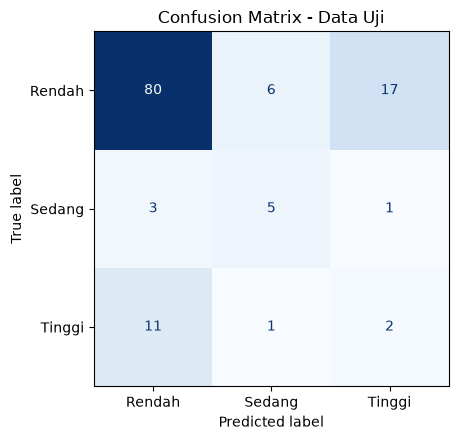

In [21]:
#Evaluasi Confusion Matrix, Accruracy, Precision, Recall, F1-Score
y_pred = rf.predict(X_te)
print(classification_report(y_te, y_pred, labels=URUTAN, digits=4))

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_te, y_pred, labels=URUTAN),
                       display_labels=[k.replace("Valuasi Relatif ", "") for k in URUTAN]
                       ).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Confusion Matrix - Data Uji")
plt.tight_layout(); plt.show()

In [22]:
importance = pd.Series(rf.feature_importances_, index=["ROE", "DER"], name="Feature Importance")
print(importance.round(4), "\n")

print("Rata-rata ROE dan DER per kategori valuasi:")
df.groupby("label")[["ROE %", "DER"]].mean().reindex(URUTAN).round(4)

ROE    0.6447
DER    0.3553
Name: Feature Importance, dtype: float64 

Rata-rata ROE dan DER per kategori valuasi:


,ROE %,DER
label,,
Valuasi Relatif Rendah,11.2533,1.1920
Valuasi Relatif Sedang,1.2124,0.9342
Valuasi Relatif Tinggi,25.9542,2.8035


In [23]:
#Analisis Sensitivitas K = 3 vs K = 4 (Ringkasan Metrik)
def evaluasi_rf(y_k):
    """Prosedur Random Forest yang sama dengan model utama, untuk label K lain."""
    X_tr_k, X_te_k, y_tr_k, y_te_k = train_test_split(
        X, y_k, test_size=0.2, stratify=y_k, random_state=RS)
    rf_k = RandomForestClassifier(n_estimators=100, class_weight="balanced",
                                  random_state=RS).fit(X_tr_k, y_tr_k)
    pred = rf_k.predict(X_te_k)
    metrik = {
        "RF Accuracy": accuracy_score(y_te_k, pred),
        "RF Precision (macro)": precision_score(y_te_k, pred, average="macro", zero_division=0),
        "RF Recall (macro)": recall_score(y_te_k, pred, average="macro", zero_division=0),
        "RF F1-Score (macro)": f1_score(y_te_k, pred, average="macro", zero_division=0),
        "RF F1-Score (weighted)": f1_score(y_te_k, pred, average="weighted", zero_division=0),
        "Kelas terkecil di data uji": int(y_te_k.value_counts().min()),
    }
    return metrik, pd.Series(rf_k.feature_importances_, index=["ROE", "DER"])


def ringkas(km_k, y_k):
    metrik_rf, imp = evaluasi_rf(y_k)
    return {"WCSS": km_k.inertia_,
            "Silhouette": silhouette_score(X_k, km_k.labels_),
            "Davies-Bouldin": davies_bouldin_score(X_k, km_k.labels_),
            "Cluster terkecil (saham)": int(np.bincount(km_k.labels_).min()),
            **metrik_rf}, imp


m_3, imp_3 = ringkas(kmeans, df["label"])
m_4, imp_4 = ringkas(km_4, df["label_k4"])

# True bila makin besar makin baik
LEBIH_BESAR = {"WCSS": False, "Silhouette": True, "Davies-Bouldin": False}
k3, k4 = "K = 3", f"K = {K_PEMBANDING}"
sensitivitas = pd.DataFrame({k3: m_3, k4: m_4})
sensitivitas["Lebih baik"] = [
    "-" if np.isclose(a, b) else (k3 if (a > b) == LEBIH_BESAR.get(m, True) else k4)
    for m, a, b in zip(sensitivitas.index, sensitivitas[k3], sensitivitas[k4])]

print(f"Unggul {k3}: {(sensitivitas['Lebih baik'] == k3).sum()} metrik")
print(f"Unggul {k4}: {(sensitivitas['Lebih baik'] == k4).sum()} metrik\n")
print("Feature Importance RF:")
print(pd.DataFrame({k3: imp_3, k4: imp_4}).round(4), "\n")
sensitivitas.round(4)


Unggul K = 3: 8 metrik
Unggul K = 4: 2 metrik

Feature Importance RF:
      K = 3   K = 4
ROE  0.6447  0.6222
DER  0.3553  0.3778 



,K = 3,K = 4,Lebih baik
WCSS,374.8293,241.5278,K = 4
Silhouette,0.6731,0.6579,K = 3
Davies-Bouldin,0.7969,0.6645,K = 4
Cluster terkecil (saham),45.0000,27.0000,K = 3
RF Accuracy,0.6905,0.6667,K = 3
RF Precision (macro),0.4559,0.4551,K = 3
RF Recall (macro),0.4917,0.4511,K = 3
RF F1-Score (macro),0.4687,0.4524,K = 3
RF F1-Score (weighted),0.7110,0.6854,K = 3
Kelas terkecil di data uji,9.0000,5.0000,K = 3
